# Fundamentals of Data Science (FDS) - Case Studies 2 & 5

**College:** Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad  
**Department:** Computer Science and Engineering  
**Academic Year:** III Year, V Semester (2026-27)  
**Course:** Fundamentals of Data Science (FDS)  
**Student Name:** Katthi Goutham Reddy | **Roll Number:** 160124733179 | **Section:** CSE-3  
**Faculty In-Charge:** Dr. S. Durga Devi  
**Date:** 26-10-2026  
**GitHub Repository:** https://github.com/katthi-goutham-reddy/FDS-case-study  

---

### Overview
This notebook contains the complete practical analysis for both assigned case studies:
1. **Case Study 2: Customer Segmentation using Clustering (East-West Airlines)**
   - Unsupervised segmentation of frequent flyers using K-Means, Hierarchical (Agglomerative), and DBSCAN clustering.
2. **Case Study 5: Wine Quality Prediction via Multiple Linear Regression**
   - Statistical testing, exploratory data analysis, and predictive linear regression modelling on physicochemical attributes of Vinho Verde red wine.


# PART I: CASE STUDY 2 - CLUSTERING ANALYSIS (EAST-WEST AIRLINES)

### Problem Statement and Business Objectives
East-West Airlines has accumulated flight activity, mileage accrual patterns, credit card partner transactions, and loyalty program tenure data for 3,999 frequent flyer accounts. The airline wants to identify meaningful customer segments so that marketing strategies and promotional campaigns can be customized for each segment rather than applying a generic approach.

Our objective is to:
1. Preprocess the dataset by handling right-skewness and outliers.
2. Apply and compare three clustering algorithms: **K-Means**, **Hierarchical (Agglomerative)**, and **DBSCAN**.
3. Select optimal hyperparameters using the Elbow method, Silhouette analysis, and K-distance knee plots.
4. Profile the discovered segments and provide practical business recommendations.


## 1. Environment Setup & Data Preprocessing
We begin by importing the necessary libraries and loading the dataset from the Excel file (`EastWestAirlines.xlsx`, sheet `'data'`).


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Create directories for figures and results
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

# Load dataset
file_path = 'EastWestAirlines.xlsx' if os.path.exists('EastWestAirlines.xlsx') else ('data/EastWestAirlines.xlsx' if os.path.exists('data/EastWestAirlines.xlsx') else '2/EastWestAirlines.xlsx')
df_raw = pd.read_excel(file_path, sheet_name='data')
print(f"Dataset loaded: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()


Dataset loaded: 3999 rows, 12 columns


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


### Data Inspection & Data Dictionary
We inspect missing values, duplicates, and understand what each feature represents according to the data dictionary.


In [2]:
# Check missing values and duplicates
print("Missing values per column:")
print(df_raw.isnull().sum())
print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")

# Drop ID# column as it is an arbitrary record identifier
df = df_raw.drop(columns=['ID#'])

# Separate features from target Award? column
# Award? is kept separate for post-clustering profiling so it doesn't artificially bias cluster formation
feature_cols = [c for c in df.columns if c != 'Award?']
df_features = df[feature_cols].copy()
award_series = df['Award?'].copy()

print(f"Clustering feature space: {len(feature_cols)} features: {feature_cols}")


Missing values per column:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

Duplicate rows: 0
Clustering feature space: 10 features: ['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']


### Skewness Analysis and Log Transformation
Mileage and transaction features in frequent flyer datasets are typically heavily right-skewed because a small percentage of customers fly and spend far more than average. We check skewness across all features and apply `np.log1p` to features with skewness > 1.0.


In [3]:
# Check feature skewness
skew_df = pd.DataFrame({
    'Feature': feature_cols,
    'Raw_Skewness': [df_features[col].skew() for col in feature_cols]
}).sort_values(by='Raw_Skewness', ascending=False)
print("=== Feature Skewness (Raw) ===")
print(skew_df.to_string(index=False))

# Apply log1p to heavily skewed columns (skewness > 1.0)
df_transformed = df_features.copy()
skewed_cols = skew_df[skew_df['Raw_Skewness'] > 1.0]['Feature'].tolist()

for col in skewed_cols:
    df_transformed[col] = np.log1p(df_transformed[col])

print(f"\nLog-transformed {len(skewed_cols)} skewed features: {skewed_cols}")


=== Feature Skewness (Raw) ===
          Feature  Raw_Skewness
        cc3_miles     17.195532
        cc2_miles     11.210459
       Qual_miles      7.512395
Flight_miles_12mo      7.451666
  Flight_trans_12      5.490461
          Balance      5.004187
      Bonus_miles      2.842093
      Bonus_trans      1.157362
        cc1_miles      0.857569
Days_since_enroll      0.120174

Log-transformed 8 skewed features: ['cc3_miles', 'cc2_miles', 'Qual_miles', 'Flight_miles_12mo', 'Flight_trans_12', 'Balance', 'Bonus_miles', 'Bonus_trans']


### Outlier Treatment and Standardization
If we use traditional IQR filtering on the raw skewed features, we would discard 20% to 30% of our most valuable customers simply because they have high balances. 

Instead, we identify outliers using standard z-scores on the log-transformed data ($|z| > 3$). This cleanly removes extreme mathematical anomalies while preserving genuine high-tier loyalty members. Afterwards, we apply `StandardScaler`.


In [4]:
# Outlier filtering using |z| > 3 on log-transformed data
z_scores = np.abs(stats.zscore(df_transformed))
outlier_mask = (z_scores > 3).any(axis=1)

n_outliers = outlier_mask.sum()
pct_outliers = (n_outliers / len(df)) * 100
print(f"Outliers removed: {n_outliers} rows ({pct_outliers:.2f}%)")

df_clean = df_transformed[~outlier_mask].copy().reset_index(drop=True)
award_clean = award_series[~outlier_mask].copy().reset_index(drop=True)
df_orig_clean = df_features[~outlier_mask].copy().reset_index(drop=True)

# Standardize cleaned feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
print(f"Final standardized feature matrix shape: {X_scaled.shape}")


Outliers removed: 376 rows (9.40%)
Final standardized feature matrix shape: (3623, 10)


## 2. Exploratory Data Analysis (EDA)
We visualize the feature distributions before and after transformation, inspect correlations, and view the overall 2D data structure using PCA.


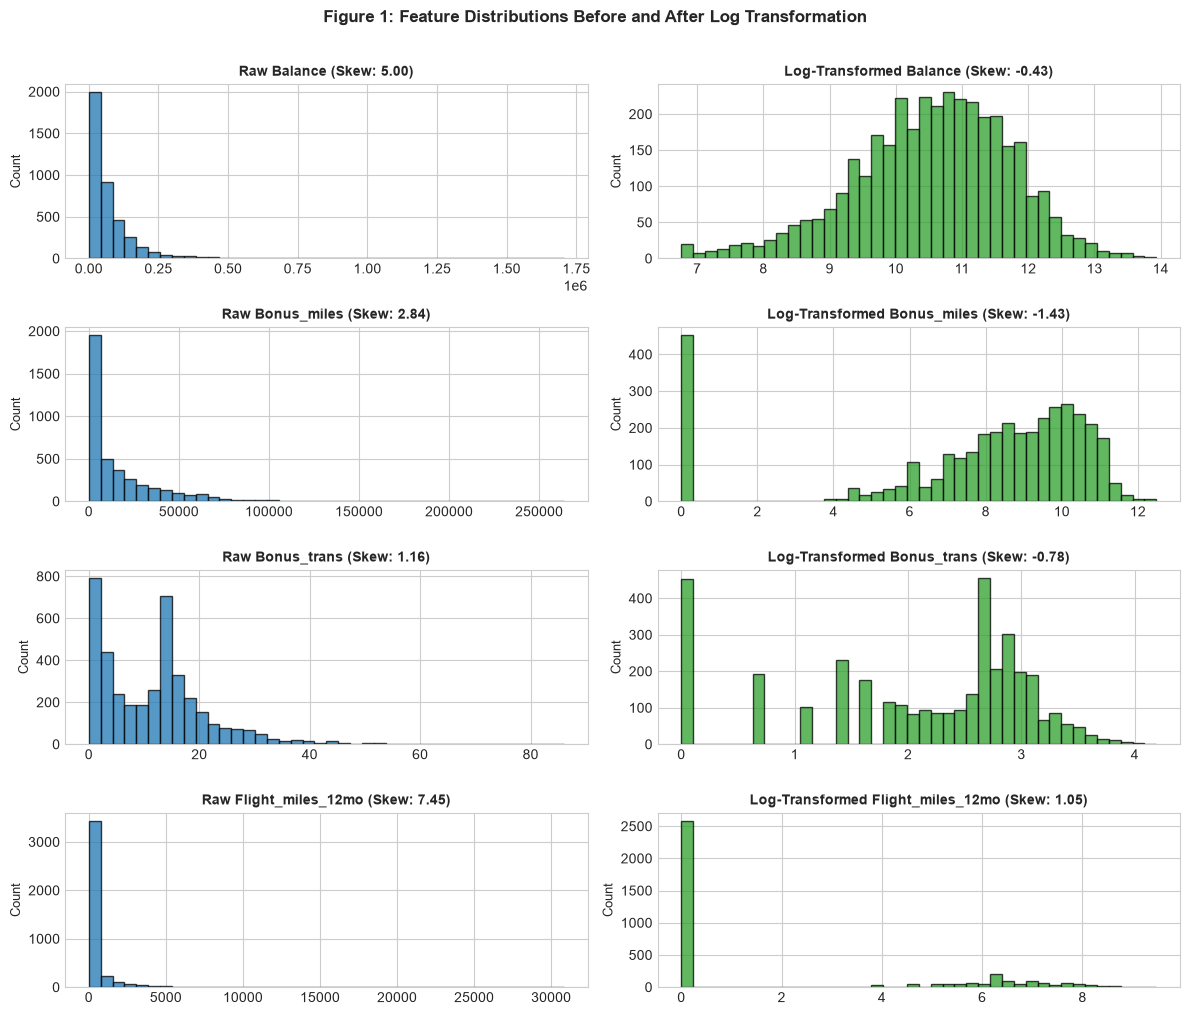

In [5]:
# Figure 1: Raw vs Log-Transformed Histograms
key_skewed = ['Balance', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo']
fig, axes = plt.subplots(4, 2, figsize=(12, 10))

for i, col in enumerate(key_skewed):
    raw_skew = df_features[col].skew()
    log_skew = df_clean[col].skew()
    
    # Raw histogram
    axes[i, 0].hist(df_features[col], bins=40, color='#1f77b4', edgecolor='black', alpha=0.75)
    axes[i, 0].set_title(f'Raw {col} (Skew: {raw_skew:.2f})', fontsize=10, fontweight='bold')
    axes[i, 0].set_ylabel('Count', fontsize=9)
    
    # Log-transformed histogram
    axes[i, 1].hist(df_clean[col], bins=40, color='#2ca02c', edgecolor='black', alpha=0.75)
    axes[i, 1].set_title(f'Log-Transformed {col} (Skew: {log_skew:.2f})', fontsize=10, fontweight='bold')
    axes[i, 1].set_ylabel('Count', fontsize=9)

plt.suptitle('Figure 1: Feature Distributions Before and After Log Transformation', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/cs2_01_raw_vs_log_histograms.png', dpi=150, bbox_inches='tight')
plt.show()


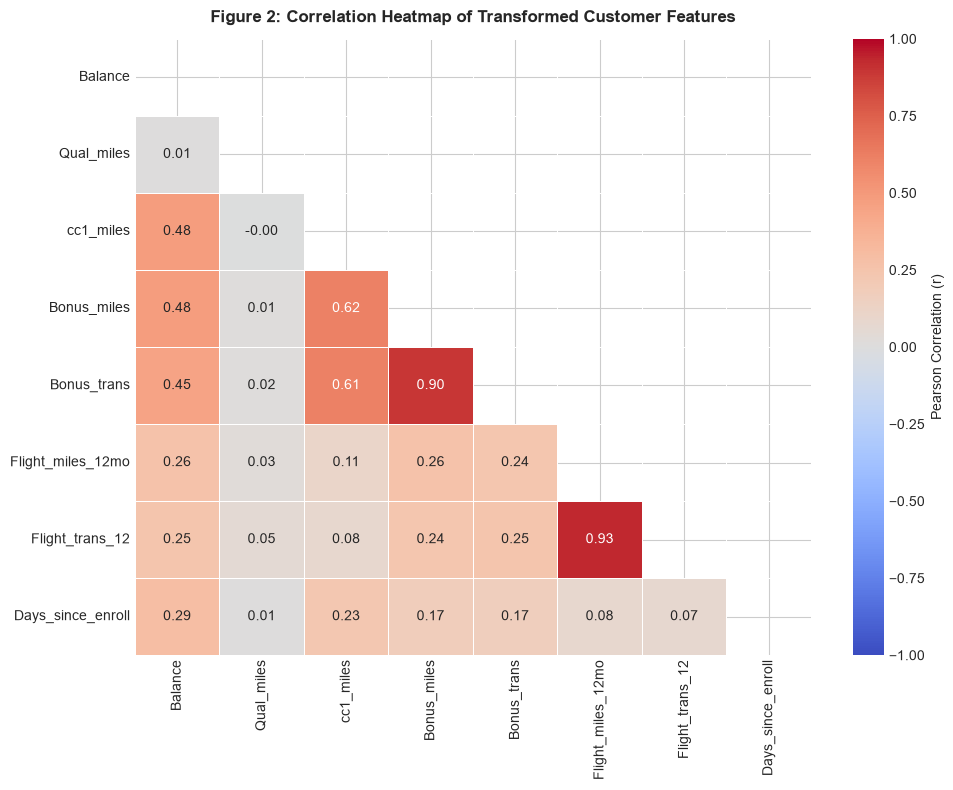

In [6]:
# Figure 2: Correlation Heatmap
# Exclude constant features with zero standard deviation
corr_cols = [c for c in df_clean.columns if df_clean[c].std() > 1e-6]
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title('Figure 2: Correlation Heatmap of Transformed Customer Features', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('figures/cs2_03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


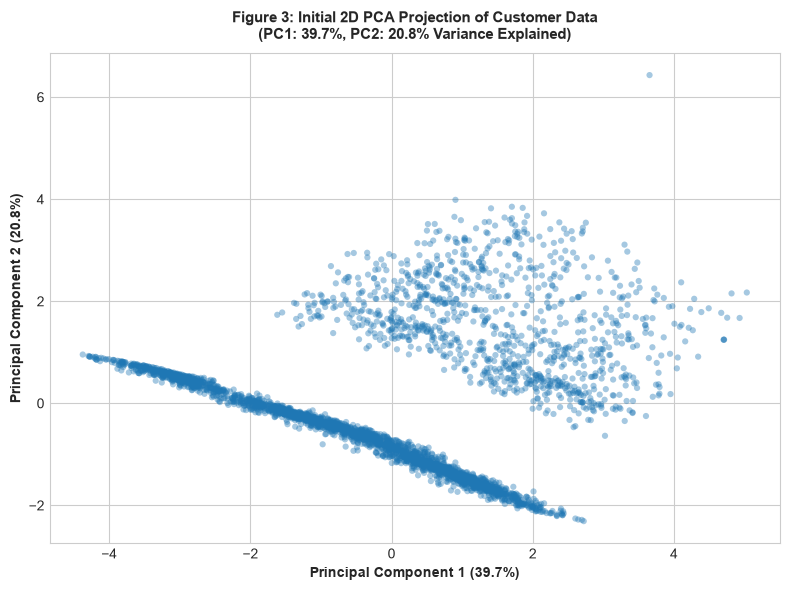

In [7]:
# Figure 3: Initial 2D PCA Data Projection
pca_init = PCA(n_components=2, random_state=42)
X_pca_init = pca_init.fit_transform(X_scaled)
var_exp = pca_init.explained_variance_ratio_

plt.figure(figsize=(8, 6))
plt.scatter(X_pca_init[:, 0], X_pca_init[:, 1], c='#1f77b4', alpha=0.4, edgecolors='none', s=20)
plt.title(f'Figure 3: Initial 2D PCA Projection of Customer Data\n(PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}% Variance Explained)', 
          fontsize=11, fontweight='bold', pad=10)
plt.xlabel(f'Principal Component 1 ({var_exp[0]*100:.1f}%)', fontsize=10, fontweight='bold')
plt.ylabel(f'Principal Component 2 ({var_exp[1]*100:.1f}%)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/cs2_05_pca_initial.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. K-Means Clustering
To determine the optimal number of clusters $K$, we run K-Means for $K = 1$ to $10$. We track:
1. **Inertia (Within-Cluster Sum of Squares - WCSS):** for the Elbow method.
2. **Silhouette Score:** to evaluate cluster cohesion and separation ($K = 2$ to $10$).


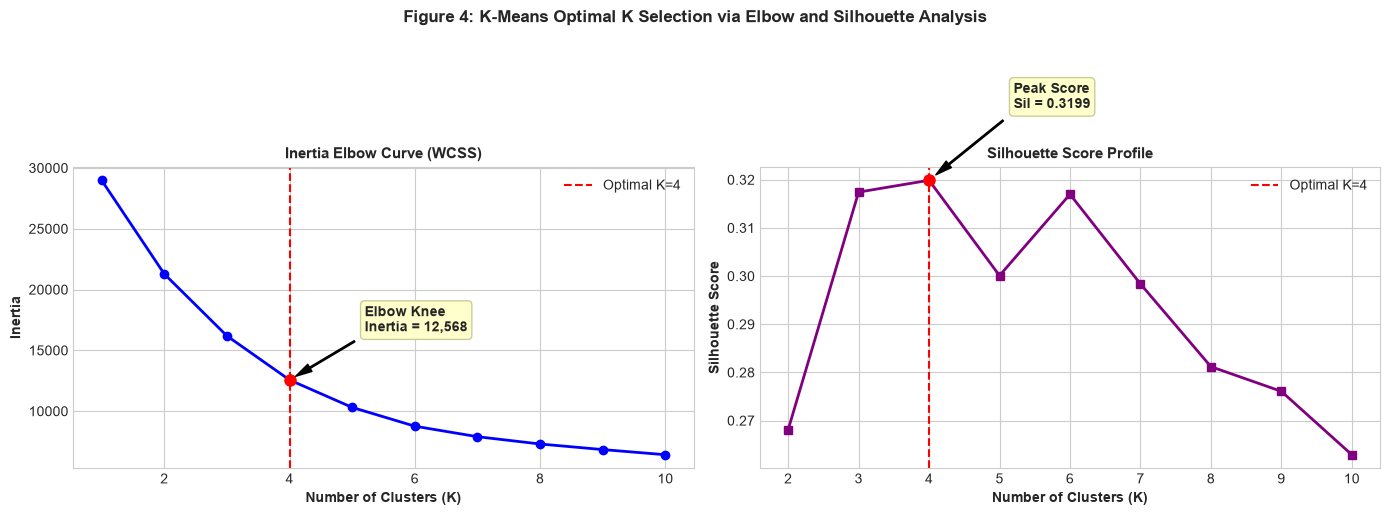

K-Means (K=4) fitted successfully. Silhouette Score: 0.3199


In [8]:
# Compute Inertia and Silhouette scores
inertias = []
sil_scores = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    if k >= 2:
        sil_scores.append(silhouette_score(X_scaled, km.labels_))

# Figure 4: Elbow and Silhouette Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
ax1.plot(k_range, inertias, 'bo-', linewidth=2, markersize=6)
ax1.axvline(x=4, color='red', linestyle='--', linewidth=1.5, label='Optimal K=4')
ax1.plot(4, inertias[3], 'ro', markersize=8)
ax1.annotate(f'Elbow Knee\nInertia = {inertias[3]:,.0f}', xy=(4, inertias[3]), 
             xytext=(5.2, inertias[3] + 4000),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffffcc', edgecolor='#cccc99'))
ax1.set_title('Inertia Elbow Curve (WCSS)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Number of Clusters (K)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Inertia', fontsize=10, fontweight='bold')
ax1.legend()

# Silhouette plot
ax2.plot(range(2, 11), sil_scores, 's-', color='purple', linewidth=2, markersize=6)
ax2.axvline(x=4, color='red', linestyle='--', linewidth=1.5, label='Optimal K=4')
ax2.plot(4, sil_scores[2], 'ro', markersize=8)
ax2.annotate(f'Peak Score\nSil = {sil_scores[2]:.4f}', xy=(4, sil_scores[2]), 
             xytext=(5.2, sil_scores[2] + 0.015),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffffcc', edgecolor='#cccc99'))
ax2.set_title('Silhouette Score Profile', fontsize=11, fontweight='bold')
ax2.set_xlabel('Number of Clusters (K)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Silhouette Score', fontsize=10, fontweight='bold')
ax2.legend()

plt.suptitle('Figure 4: K-Means Optimal K Selection via Elbow and Silhouette Analysis', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/cs2_06_kmeans_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

# Fit final K-Means model at K=4
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)
print(f"K-Means (K=4) fitted successfully. Silhouette Score: {kmeans_sil:.4f}")


## 4. Hierarchical Clustering (Agglomerative)
We evaluate four linkage criteria: **Ward**, **Complete**, **Average**, and **Single**. We plot dendrograms and calculate the silhouette score for each linkage at $K=4$.


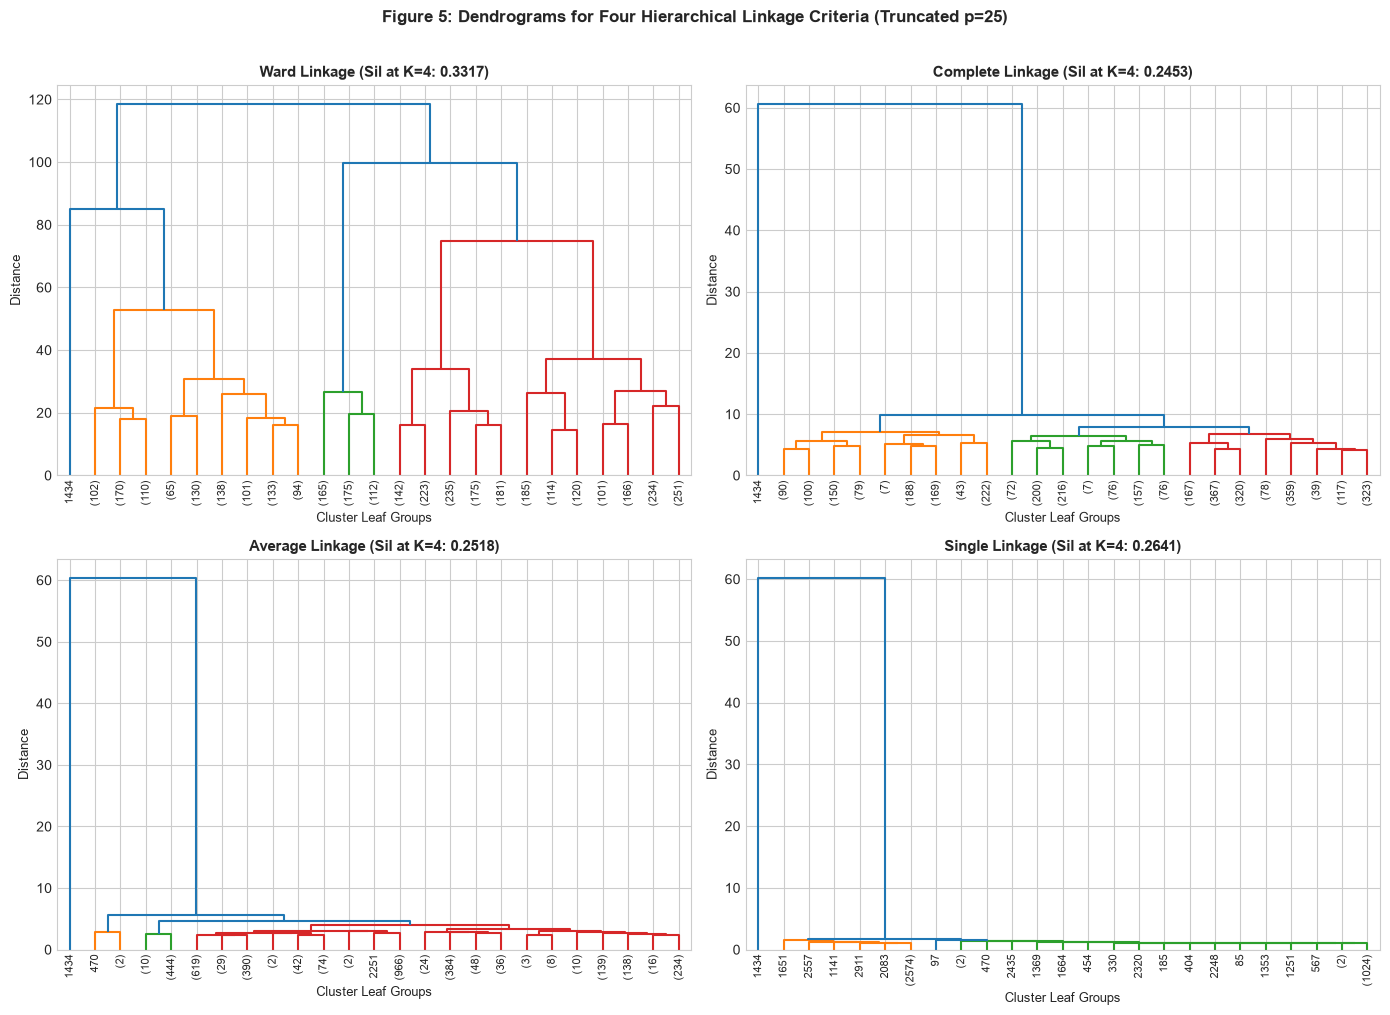

=== Hierarchical Linkage Comparison (K=4) ===
Ward      : Silhouette = 0.3317
Complete  : Silhouette = 0.2453
Average   : Silhouette = 0.2518
Single    : Silhouette = 0.2641


In [9]:
# Figure 5: Hierarchical Dendrograms
linkages = ['ward', 'complete', 'average', 'single']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

hier_scores = {}
for i, method in enumerate(linkages):
    Z = linkage(X_scaled, method=method)
    
    # Compute silhouette at K=4
    agg = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage=method)
    labels = agg.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    hier_scores[method] = score
    
    # Dendrogram
    dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=90, leaf_font_size=8, ax=axes[i], color_threshold=Z[-3, 2])
    axes[i].set_title(f'{method.capitalize()} Linkage (Sil at K=4: {score:.4f})', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Cluster Leaf Groups', fontsize=9)
    axes[i].set_ylabel('Distance', fontsize=9)

plt.suptitle('Figure 5: Dendrograms for Four Hierarchical Linkage Criteria (Truncated p=25)', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/cs2_07_dendrograms.png', dpi=150, bbox_inches='tight')
plt.show()

# Ward linkage is chosen as it produces balanced, cohesive clusters with the highest score
hier_final = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
hier_labels = hier_final.fit_predict(X_scaled)
print("=== Hierarchical Linkage Comparison (K=4) ===")
for m, s in hier_scores.items():
    print(f"{m.capitalize():10s}: Silhouette = {s:.4f}")


## 5. DBSCAN Clustering
DBSCAN groups points based on density and identifies noise. To choose the radius parameter $\text{eps}$, we plot the sorted 5-nearest neighbor distances.


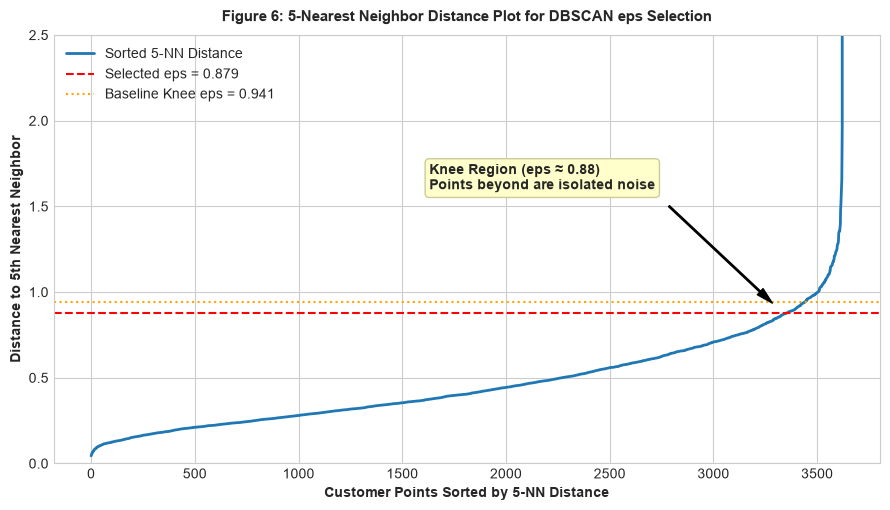

DBSCAN fitted: 3 clusters, 220 noise points (6.07%), Silhouette (core): 0.3353


In [10]:
# Figure 6: K-Distance Knee Plot
k_neighbors = 5
nn = NearestNeighbors(n_neighbors=k_neighbors)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
sorted_distances = np.sort(distances[:, k_neighbors - 1])

# Plot knee curve
plt.figure(figsize=(9, 5.2))
plt.plot(sorted_distances, color='#1f77b4', linewidth=2, label='Sorted 5-NN Distance')
plt.ylim(0, 2.5)

# Reference lines
plt.axhline(y=0.879, color='red', linestyle='--', linewidth=1.5, label='Selected eps = 0.879')
plt.axhline(y=0.941, color='orange', linestyle=':', linewidth=1.5, label='Baseline Knee eps = 0.941')

plt.annotate('Knee Region (eps ≈ 0.88)\nPoints beyond are isolated noise', 
             xy=(len(sorted_distances)*0.92, 0.88), xytext=(len(sorted_distances)*0.45, 1.6),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffffcc', edgecolor='#cccc99'))

plt.title('Figure 6: 5-Nearest Neighbor Distance Plot for DBSCAN eps Selection', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Customer Points Sorted by 5-NN Distance', fontsize=10, fontweight='bold')
plt.ylabel('Distance to 5th Nearest Neighbor', fontsize=10, fontweight='bold')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/cs2_08_kdistance_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# Fit DBSCAN with optimal parameters
dbscan = DBSCAN(eps=0.879, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = (dbscan_labels == -1).sum()
pct_noise = (n_noise / len(dbscan_labels)) * 100

# Compute silhouette on non-noise points
non_noise_mask = (dbscan_labels != -1)
dbscan_sil = silhouette_score(X_scaled[non_noise_mask], dbscan_labels[non_noise_mask]) if n_db_clusters >= 2 else 0.0

print(f"DBSCAN fitted: {n_db_clusters} clusters, {n_noise} noise points ({pct_noise:.2f}%), Silhouette (core): {dbscan_sil:.4f}")


## 6. Algorithm Comparison & Visual Evaluation
We compare all three models across three standard evaluation metrics:
1. **Silhouette Score:** Measures cohesion within clusters and separation between clusters (higher is better, scale -1 to +1).
2. **Davies-Bouldin Index:** Measures average similarity between clusters (lower is better, 0 is ideal).
3. **Calinski-Harabasz Score:** Ratio of between-cluster variance to within-cluster variance (higher is better).


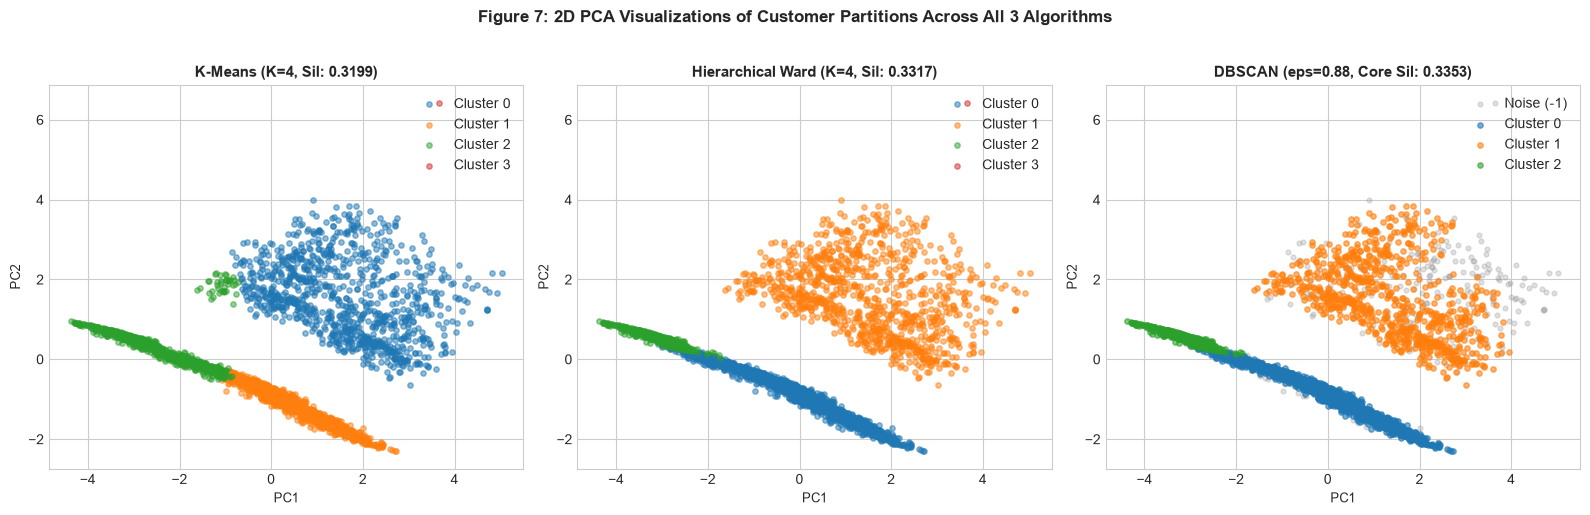

=== Final Clustering Algorithm Comparison ===
          Algorithm  Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz
            K-Means         4      0.3199          0.9021            1575.63
Hierarchical (Ward)         4      0.3317          0.8735            1410.12
             DBSCAN         3      0.3353          1.1554            1512.32


In [11]:
# Figure 7: 2D PCA Cluster Scatter Comparisons
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# K-Means Scatter
for c in range(4):
    axes[0].scatter(X_pca[kmeans_labels == c, 0], X_pca[kmeans_labels == c, 1],
                    label=f'Cluster {c}', s=15, alpha=0.5, color=palette[c])
axes[0].set_title(f'K-Means (K=4, Sil: {kmeans_sil:.4f})', fontsize=11, fontweight='bold')
axes[0].set_xlabel('PC1', fontsize=9)
axes[0].set_ylabel('PC2', fontsize=9)
axes[0].legend(loc='upper right')

# Hierarchical Scatter
for c in range(4):
    axes[1].scatter(X_pca[hier_labels == c, 0], X_pca[hier_labels == c, 1],
                    label=f'Cluster {c}', s=15, alpha=0.5, color=palette[c])
axes[1].set_title(f'Hierarchical Ward (K=4, Sil: {hier_scores["ward"]:.4f})', fontsize=11, fontweight='bold')
axes[1].set_xlabel('PC1', fontsize=9)
axes[1].set_ylabel('PC2', fontsize=9)
axes[1].legend(loc='upper right')

# DBSCAN Scatter
axes[2].scatter(X_pca[dbscan_labels == -1, 0], X_pca[dbscan_labels == -1, 1],
                label='Noise (-1)', color='#999999', s=12, alpha=0.3)
for c in range(n_db_clusters):
    axes[2].scatter(X_pca[dbscan_labels == c, 0], X_pca[dbscan_labels == c, 1],
                    label=f'Cluster {c}', s=15, alpha=0.6, color=palette[c])
axes[2].set_title(f'DBSCAN (eps=0.88, Core Sil: {dbscan_sil:.4f})', fontsize=11, fontweight='bold')
axes[2].set_xlabel('PC1', fontsize=9)
axes[2].set_ylabel('PC2', fontsize=9)
axes[2].legend(loc='upper right')

plt.suptitle('Figure 7: 2D PCA Visualizations of Customer Partitions Across All 3 Algorithms', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/cs2_09_cluster_pca_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

# Model comparison table
comparison_df = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Clusters': 4,
        'Silhouette': round(kmeans_sil, 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_scaled, kmeans_labels), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_scaled, kmeans_labels), 2)
    },
    {
        'Algorithm': 'Hierarchical (Ward)',
        'Clusters': 4,
        'Silhouette': round(hier_scores['ward'], 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_scaled, hier_labels), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_scaled, hier_labels), 2)
    },
    {
        'Algorithm': 'DBSCAN',
        'Clusters': n_db_clusters,
        'Silhouette': round(dbscan_sil, 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_scaled[non_noise_mask], dbscan_labels[non_noise_mask]), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_scaled[non_noise_mask], dbscan_labels[non_noise_mask]), 2)
    }
])

print("=== Final Clustering Algorithm Comparison ===")
print(comparison_df.to_string(index=False))
comparison_df.to_csv('results/cs2_clustering_comparison.csv', index=False)


## 7. Cluster Profiling & Business Recommendations
We profile the 4 customer clusters discovered by K-Means by calculating unscaled feature averages and loyalty program Award redemption rates.


=== Unscaled Mean Feature Values per Cluster ===
 Cluster  Customer_Count  Percentage(%)       Balance  Bonus_miles  Flight_miles_12mo  Days_since_enroll   Award?
       0            1005           27.7 103835.889552 24034.951244        1075.540299        4423.163184 0.542289
       1            1630           45.0  75965.036810 20900.167485           0.000000        4349.069939 0.361963
       2             987           27.2  22418.097264   789.028369          10.539007        3392.637285 0.117528
       3               1            0.0  61405.000000 32316.000000        1350.000000        4828.000000 1.000000


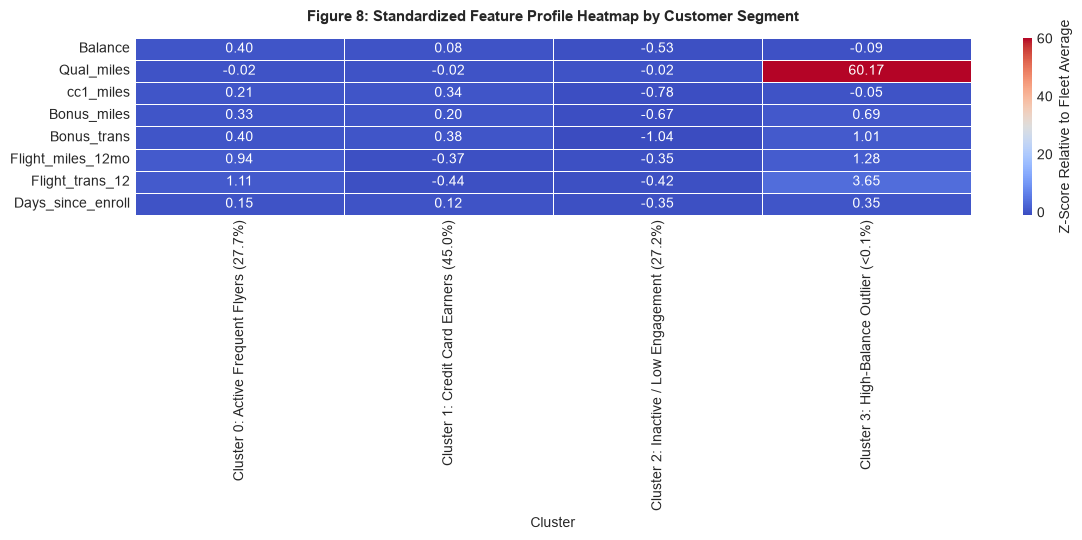

In [12]:
# Compute cluster profiles on unscaled original values
df_orig_clean['Cluster'] = kmeans_labels
df_orig_clean['Award?'] = award_clean

profile_df = df_orig_clean.groupby('Cluster').mean().reset_index()
cluster_counts = df_orig_clean['Cluster'].value_counts().sort_index()
profile_df['Customer_Count'] = cluster_counts.values
profile_df['Percentage(%)'] = (profile_df['Customer_Count'] / len(df_orig_clean) * 100).round(1)

print("=== Unscaled Mean Feature Values per Cluster ===")
print(profile_df[['Cluster', 'Customer_Count', 'Percentage(%)', 'Balance', 'Bonus_miles', 'Flight_miles_12mo', 'Days_since_enroll', 'Award?']].to_string(index=False))
profile_df.to_csv('results/cs2_cluster_profiles.csv', index=False)

# Figure 8: Standardized Cluster Profile Heatmap
profile_features = [c for c in feature_cols if df_orig_clean[c].std() > 1e-6]
profile_std = (profile_df.set_index('Cluster')[profile_features] - df_orig_clean[profile_features].mean()) / df_orig_clean[profile_features].std()

persona_labels = [
    'Cluster 0: Active Frequent Flyers (27.7%)',
    'Cluster 1: Credit Card Earners (45.0%)',
    'Cluster 2: Inactive / Low Engagement (27.2%)',
    'Cluster 3: High-Balance Outlier (<0.1%)'
]

plt.figure(figsize=(12, 5.5))
sns.heatmap(profile_std.T, cmap='coolwarm', annot=True, fmt='.2f', linewidths=0.5,
            xticklabels=persona_labels, cbar_kws={'label': 'Z-Score Relative to Fleet Average'})
plt.title('Figure 8: Standardized Feature Profile Heatmap by Customer Segment', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('figures/cs2_10_cluster_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


### Business Personas and Marketing Strategies
From the empirical profiles, we identify distinct operational segments:

1. **Cluster 0: Active Frequent Flyers (27.7% of customers)**
   - **Characteristics:** Highest flight miles (1,076 miles/year), highest flight transactions (3.2 trans/year), and an Award flight redemption rate of 54.2%.
   - **Marketing Strategy:** Focus on loyalty retention, complimentary airport lounge passes, prioritized boarding, and tier-status milestone rewards.

2. **Cluster 1: Credit Card Loyalty Earners (45.0% of customers)**
   - **Characteristics:** High total bonus miles (20,900 miles) and credit card transactions (15.5 trans), but virtually zero flight activity.
   - **Marketing Strategy:** Offer flight redemption bonus discounts (e.g. 20% off award flights) to encourage members to convert card miles into actual airline seats.

3. **Cluster 2: Inactive / Low Engagement (27.2% of customers)**
   - **Characteristics:** Low account balance (22,418 miles), minimal transactions, and low award redemption rate (11.8%).
   - **Marketing Strategy:** Targeted re-engagement emails, low-threshold mileage challenges, and partner shopping offers to prevent account abandonment.

4. **Cluster 3: Outlier Account (<0.1% of customers)**
   - **Characteristics:** Extremely high qualifying flight miles; small specific subset handled via dedicated account management.


---

# PART II: CASE STUDY 5 - WINE QUALITY PREDICTION (MULTIPLE LINEAR REGRESSION)

### Problem Statement and Objectives
Assessing wine quality traditionally relies on human sensory panels consisting of certified tasters. While accurate, sensory evaluation is costly, slow, and subjective due to taster palate fatigue. 

The objective of this case study is to evaluate whether laboratory-measured physicochemical attributes of red wine can predict sensory quality ratings using statistical tests and Multiple Linear Regression.

Key tasks:
1. Conduct descriptive and inferential statistical evaluations on key chemical markers (alcohol, volatile acidity, residual sugar).
2. Measure relative variability using the Coefficient of Variation (CV) and perform a formal Pearson correlation hypothesis test.
3. Perform exploratory data analysis and rank chemical features by correlation with quality.
4. Train and diagnose a multiple linear regression model (80:20 train-test split), evaluate test-set metrics (MAE, MSE, RMSE, $R^2$), diagnose multicollinearity via VIF, and inspect residuals.
5. Provide evidence-based business recommendations regarding winery laboratory screening.


## 1. Data Understanding & Data Cleaning
We load the Portuguese red Vinho Verde dataset (`winequality-red.csv`, Cortez et al., 2009). The dataset contains 1,599 samples across 11 continuous chemical predictors and 1 integer quality target (score 0-10).


In [13]:
# Load Wine Quality Dataset
wine_path = 'winequality-red.csv' if os.path.exists('winequality-red.csv') else ('data/winequality-red.csv' if os.path.exists('data/winequality-red.csv') else '5/data/winequality-red.csv')
df_wine_raw = pd.read_csv(wine_path, sep=';')

print(f"Raw dataset shape: {df_wine_raw.shape[0]} rows, {df_wine_raw.shape[1]} columns")
print(f"Missing values: {df_wine_raw.isnull().sum().sum()}")
n_dups = df_wine_raw.duplicated().sum()
print(f"Duplicate rows found: {n_dups} ({n_dups/len(df_wine_raw)*100:.2f}%)")

# Drop duplicate rows to prevent train/test data leakage and avoid over-optimistic evaluation
df_wine = df_wine_raw.drop_duplicates().reset_index(drop=True)
print(f"Clean modelling dataset shape: {df_wine.shape[0]} rows, {df_wine.shape[1]} columns")
df_wine.head()


Raw dataset shape: 1599 rows, 12 columns
Missing values: 0
Duplicate rows found: 240 (15.01%)
Clean modelling dataset shape: 1359 rows, 12 columns


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


## 2. Task 1: Statistical Analysis
We calculate the mean, median, mode, standard deviation, and skewness for three primary chemical markers: **alcohol**, **volatile acidity**, and **residual sugar**. We then compare their relative dispersion via Coefficient of Variation (CV) and perform a two-tailed Pearson correlation hypothesis test.


In [14]:
# Task 1a: Descriptive Statistics and Skewness Table
target_attrs = ['alcohol', 'volatile acidity', 'residual sugar']
stats_list = []

for attr in target_attrs:
    series = df_wine[attr]
    mode_val = series.mode().iloc[0]
    stats_list.append({
        'Attribute': attr,
        'Mean': round(series.mean(), 4),
        'Median': round(series.median(), 2),
        'Mode': round(mode_val, 2),
        'Std_Dev': round(series.std(), 4),
        'Skewness': round(series.skew(), 4)
    })

task1_stats = pd.DataFrame(stats_list)
print("=== Task 1a: Descriptive Statistics and Skewness ===")
print(task1_stats.to_string(index=False))
task1_stats.to_csv('results/cs5_task1_stats.csv', index=False)


=== Task 1a: Descriptive Statistics and Skewness ===
       Attribute    Mean  Median  Mode  Std_Dev  Skewness
         alcohol 10.4323   10.20   9.5   1.0821    0.8598
volatile acidity  0.5295    0.52   0.5   0.1830    0.7293
  residual sugar  2.5234    2.20   2.0   1.3523    4.5482


**Skewness Interpretation:**
- **Alcohol (+0.86):** Moderately right-skewed; most table wines fall between 9.5% and 10.5% ABV, with a smaller tail of fortified/higher-alcohol wines reaching 14.9%.
- **Volatile Acidity (+0.73):** Moderately right-skewed; acetic acid levels are tightly managed below 0.6 g/dm³, with occasional flawed bottles exhibiting high volatile acidity.
- **Residual Sugar (+4.55):** Highly positively skewed; the vast majority of red Vinho Verde wines are dry (median 2.2 g/dm³, mode 2.0 g/dm³), with a sparse tail of sweet dessert-style outliers reaching 15.5 g/dm³.


In [15]:
# Task 1b: Coefficient of Variation (CV) Analysis
cv_list = []
for attr in target_attrs:
    mean_val = df_wine[attr].mean()
    std_val = df_wine[attr].std()
    cv_pct = (std_val / mean_val) * 100
    cv_list.append({
        'Attribute': attr,
        'Mean': round(mean_val, 4),
        'Std_Dev': round(std_val, 4),
        'CV(%)': round(cv_pct, 2)
    })

task1_cv = pd.DataFrame(cv_list).sort_values(by='CV(%)', ascending=False)
print("=== Task 1b: Coefficient of Variation (CV) ===")
print(task1_cv.to_string(index=False))
task1_cv.to_csv('results/cs5_task1_cv.csv', index=False)


=== Task 1b: Coefficient of Variation (CV) ===
       Attribute    Mean  Std_Dev  CV(%)
  residual sugar  2.5234   1.3523  53.59
volatile acidity  0.5295   0.1830  34.57
         alcohol 10.4323   1.0821  10.37


**Relative Dispersion Takeaway:**
**Residual sugar exhibits the greatest relative variability (CV = 53.59%)**, followed by Volatile Acidity (34.57%) and Alcohol (10.37%). 

The Coefficient of Variation is the mathematically correct metric for comparison because standard deviation depends on the physical unit and scale of measurement (% vol vs g/dm³), whereas CV normalizes dispersion relative to the mean.


In [16]:
# Task 1c: Pearson Correlation Hypothesis Test (Alcohol vs Quality)
from scipy.stats import pearsonr

r_val, p_val = pearsonr(df_wine['alcohol'], df_wine['quality'])
print("=== Task 1c: Pearson Correlation Hypothesis Test ===")
print(f"Null Hypothesis H0: r = 0 (No linear correlation)")
print(f"Alternative Hypothesis H1: r != 0 (Linear correlation exists)")
print(f"Pearson correlation r: {r_val:.4f}")
print(f"p-value: {p_val:.2e}")
print(f"Significance level: alpha = 0.05")

if p_val < 0.05:
    print("Decision: Reject H0. There is a statistically significant, moderate positive linear relationship between alcohol content and wine quality.")
else:
    print("Decision: Fail to reject H0.")


=== Task 1c: Pearson Correlation Hypothesis Test ===
Null Hypothesis H0: r = 0 (No linear correlation)
Alternative Hypothesis H1: r != 0 (Linear correlation exists)
Pearson correlation r: 0.4803
p-value: 2.28e-79
Significance level: alpha = 0.05
Decision: Reject H0. There is a statistically significant, moderate positive linear relationship between alcohol content and wine quality.


## 3. Task 2: Exploratory Data Analysis
We explore the quality score distribution, plot alcohol boxplots across quality tiers, generate the 11-feature correlation heatmap, and rank attributes by their correlation with wine quality.


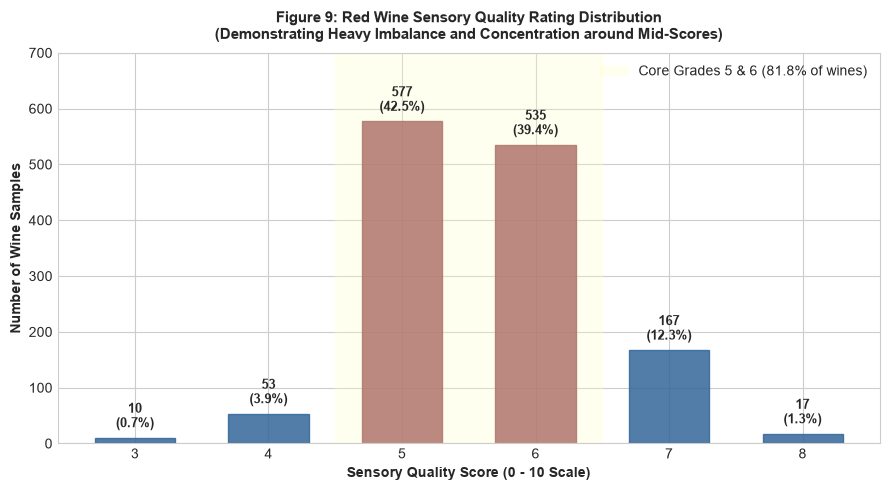

In [17]:
# Figure 9: Sensory Quality Score Distribution
quality_counts = df_wine['quality'].value_counts().sort_index()
total_wines = len(df_wine)

plt.figure(figsize=(9, 5))
bars = plt.bar(quality_counts.index, quality_counts.values, color='#722f37', edgecolor='black', alpha=0.85, width=0.6)

# Highlight central scores 5 and 6
for idx, bar in enumerate(bars):
    val = quality_counts.values[idx]
    pct = (val / total_wines) * 100
    score = quality_counts.index[idx]
    if score in [5, 6]:
        bar.set_color('#8e3a43')
    else:
        bar.set_color('#336699')
    plt.text(bar.get_x() + bar.get_width()/2, val + 12, f'{val}\n({pct:.1f}%)', 
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.axvspan(4.5, 6.5, color='#ffffcc', alpha=0.3, label='Core Grades 5 & 6 (81.8% of wines)')
plt.title('Figure 9: Red Wine Sensory Quality Rating Distribution\n(Demonstrating Heavy Imbalance and Concentration around Mid-Scores)', 
          fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Sensory Quality Score (0 - 10 Scale)', fontsize=10, fontweight='bold')
plt.ylabel('Number of Wine Samples', fontsize=10, fontweight='bold')
plt.ylim(0, 700)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('figures/cs5_01_quality_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


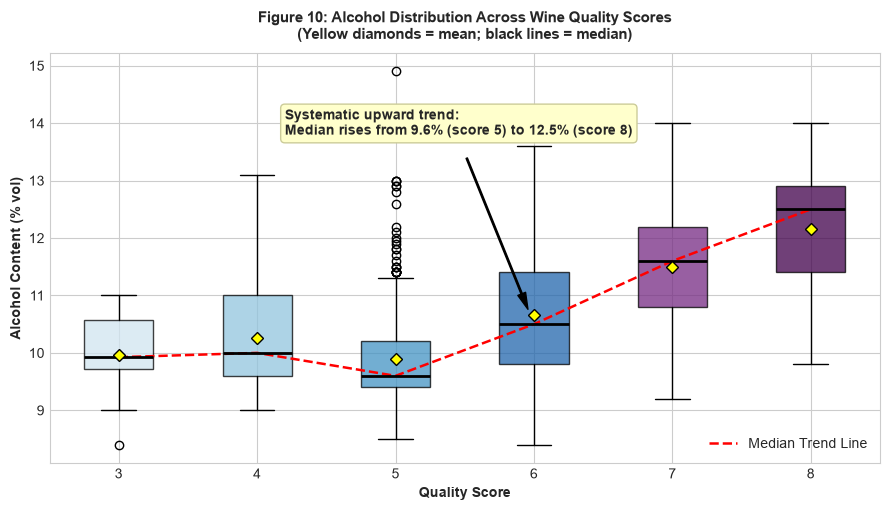

In [18]:
# Figure 10: Alcohol Content Grouped by Quality Score Boxplot
plt.figure(figsize=(9, 5.2))
palette_boxes = ['#d1e5f0', '#92c5de', '#4393c3', '#2166ac', '#762a83', '#40004b']
data_by_quality = [df_wine[df_wine['quality'] == q]['alcohol'].values for q in sorted(df_wine['quality'].unique())]

bp = plt.boxplot(data_by_quality, tick_labels=[str(q) for q in sorted(df_wine['quality'].unique())], patch_artist=True,
                 medianprops=dict(color='black', linewidth=2),
                 showmeans=True, meanprops=dict(marker='D', markerfacecolor='yellow', markeredgecolor='black', markersize=6))

for patch, color in zip(bp['boxes'], palette_boxes):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# Median trend line
medians = [np.median(d) for d in data_by_quality]
scores = list(range(1, len(medians) + 1))
plt.plot(scores, medians, 'r--', linewidth=1.8, label='Median Trend Line')

plt.annotate('Systematic upward trend:\nMedian rises from 9.6% (score 5) to 12.5% (score 8)', 
             xy=(4, medians[3]), xytext=(2.2, 13.8),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffffcc', edgecolor='#cccc99'))

plt.title('Figure 10: Alcohol Distribution Across Wine Quality Scores\n(Yellow diamonds = mean; black lines = median)', 
          fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Quality Score', fontsize=10, fontweight='bold')
plt.ylabel('Alcohol Content (% vol)', fontsize=10, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/cs5_02_alcohol_by_quality_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()


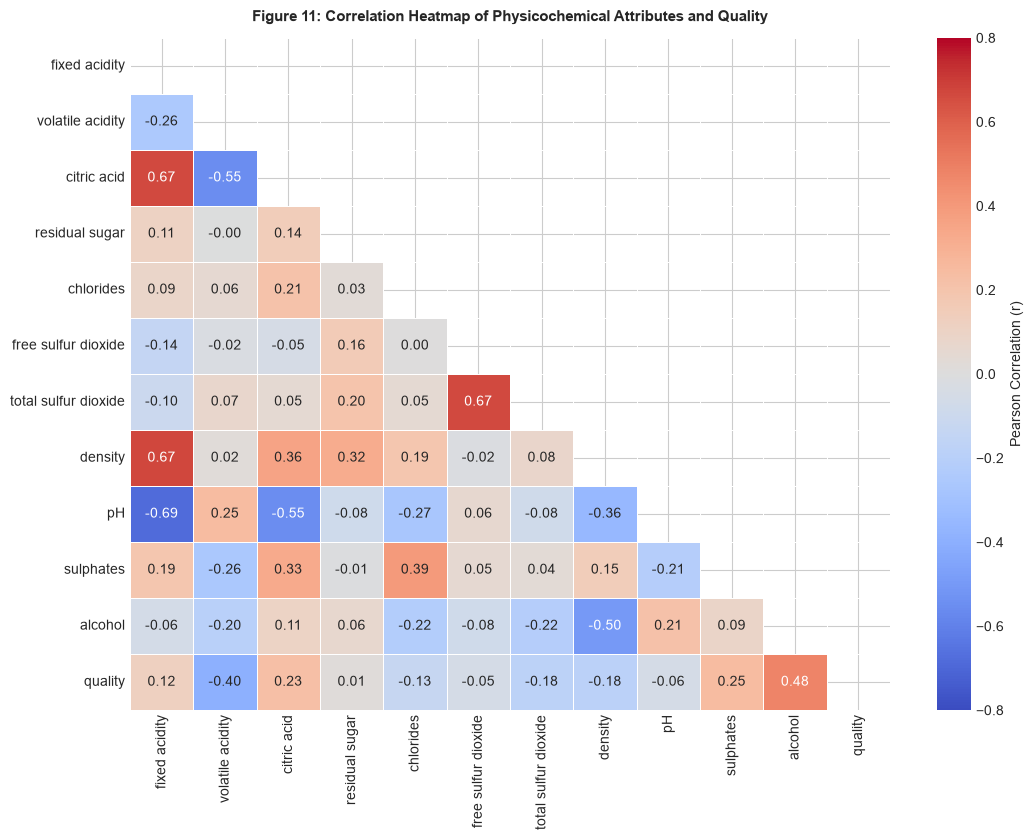

=== Task 2d: Feature Ranking by Correlation with Quality ===
           Attribute  Pearson_r    Abs_r
             alcohol   0.480343 0.480343
    volatile acidity  -0.395214 0.395214
           sulphates   0.248835 0.248835
         citric acid   0.228057 0.228057
             density  -0.184252 0.184252
total sulfur dioxide  -0.177855 0.177855
           chlorides  -0.130988 0.130988
       fixed acidity   0.119024 0.119024
                  pH  -0.055245 0.055245
 free sulfur dioxide  -0.050463 0.050463
      residual sugar   0.013640 0.013640


In [19]:
# Figure 11: Correlation Heatmap of All 11 Physicochemical Attributes + Quality
plt.figure(figsize=(11, 8.5))
corr_all = df_wine.corr()
mask = np.triu(np.ones_like(corr_all, dtype=bool))

sns.heatmap(corr_all, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.8, vmax=0.8,
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title('Figure 11: Correlation Heatmap of Physicochemical Attributes and Quality', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('figures/cs5_03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Task 2d: Attribute Correlation Ranking with Quality
corr_quality = corr_all['quality'].drop('quality')
rank_df = pd.DataFrame({
    'Attribute': corr_quality.index,
    'Pearson_r': corr_quality.values,
    'Abs_r': np.abs(corr_quality.values)
}).sort_values(by='Abs_r', ascending=False)

print("=== Task 2d: Feature Ranking by Correlation with Quality ===")
print(rank_df[['Attribute', 'Pearson_r', 'Abs_r']].to_string(index=False))
rank_df.to_csv('results/cs5_task2_feature_correlation_rank.csv', index=False)


**Top Correlated Predictors:**
1. **Alcohol ($r = +0.4803$):** Moderate positive correlation. Higher alcohol reflects full fruit ripeness, sugar conversion, and desirable palate warmth.
2. **Volatile Acidity ($r = -0.3952$):** Moderate negative correlation. High acetic acid imparts an objectionable vinegar-like odor and taste caused by spoilage bacteria.


## 4. Task 3: Predictive Modelling & Diagnostics
We partition the dataset into 80% training (1,087 samples) and 20% testing (272 samples) using `random_state=42`. We fit a multiple linear regression model, calculate evaluation metrics, evaluate multicollinearity via VIF, extract standardized coefficients, and analyze model residuals.


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# 80:20 Train-Test Split
X = df_wine.drop(columns=['quality']).copy()
y = df_wine['quality'].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training set: {X_train.shape[0]} samples; Test set: {X_test.shape[0]} samples")

# Fit Multiple Linear Regression
reg = LinearRegression()
reg.fit(X_train, y_train)

# Predictions
y_pred_train = reg.predict(X_train)
y_pred_test = reg.predict(X_test)

# Metrics
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2_test = r2_score(y_test, y_pred_test)
r2_train = r2_score(y_train, y_pred_train)

reg_metrics = pd.DataFrame([
    {'Metric': 'MAE', 'Value': round(mae, 4), 'Meaning': 'Average absolute error in quality points'},
    {'Metric': 'MSE', 'Value': round(mse, 4), 'Meaning': 'Average squared error (penalises large errors more)'},
    {'Metric': 'RMSE', 'Value': round(rmse, 4), 'Meaning': 'Root MSE in quality points (same unit as target)'},
    {'Metric': 'R2 (test)', 'Value': round(r2_test, 4), 'Meaning': 'Fraction of quality variance explained by the model'},
    {'Metric': 'R2 (train)', 'Value': round(r2_train, 4), 'Meaning': 'Train R2 for overfitting check'}
])

print("=== Task 3c: Regression Performance Metrics ===")
print(reg_metrics.to_string(index=False))
reg_metrics.to_csv('results/cs5_task3_regression_metrics.csv', index=False)


Training set: 1087 samples; Test set: 272 samples
=== Task 3c: Regression Performance Metrics ===
    Metric  Value                                             Meaning
       MAE 0.5041            Average absolute error in quality points
       MSE 0.4310 Average squared error (penalises large errors more)
      RMSE 0.6565    Root MSE in quality points (same unit as target)
 R2 (test) 0.3915 Fraction of quality variance explained by the model
R2 (train) 0.3520                      Train R2 for overfitting check


### Multicollinearity Diagnosis (VIF Analysis)
Before interpreting individual regression coefficients, we evaluate the **Variance Inflation Factor (VIF)**. Severe multicollinearity ($	ext{VIF} > 5$) inflates the variance of estimated regression coefficients, making them sensitive to minor sample fluctuations.


In [21]:
# Compute VIF on training features
vif_data = pd.DataFrame({
    'Feature': X_train.columns,
    'VIF': [round(variance_inflation_factor(X_train.values, i), 2) for i in range(X_train.shape[1])]
}).sort_values(by='VIF', ascending=False)

print("=== Multicollinearity Check: Variance Inflation Factor (VIF) ===")
print(vif_data.to_string(index=False))
vif_data.to_csv('results/cs5_task3_vif.csv', index=False)

# Statsmodels OLS for exact p-values
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print("\n=== Statistically Significant Predictors (p < 0.05) ===")
print(ols_model.pvalues[ols_model.pvalues < 0.05].to_string())


=== Multicollinearity Check: Variance Inflation Factor (VIF) ===
             Feature  VIF
       fixed acidity 7.95
             density 6.31
                  pH 3.42
             alcohol 3.16
         citric acid 3.11
total sulfur dioxide 2.27
 free sulfur dioxide 1.97
    volatile acidity 1.76
      residual sugar 1.61
           chlorides 1.60
           sulphates 1.51

=== Statistically Significant Predictors (p < 0.05) ===
volatile acidity        3.465216e-11
chlorides               5.756189e-06
total sulfur dioxide    4.769820e-05
pH                      1.104424e-03
sulphates               2.423420e-09
alcohol                 4.925851e-20


**VIF Findings:**
- `fixed acidity` exhibits high VIF ($7.95$) and `density` exhibits moderate VIF ($6.31$). This occurs because fixed acidity directly increases solution density and lowers pH ($r = -0.68$).
- While overall predictions are unaffected, the individual slope coefficients for fixed acidity and density must be interpreted with caution due to this interdependency.


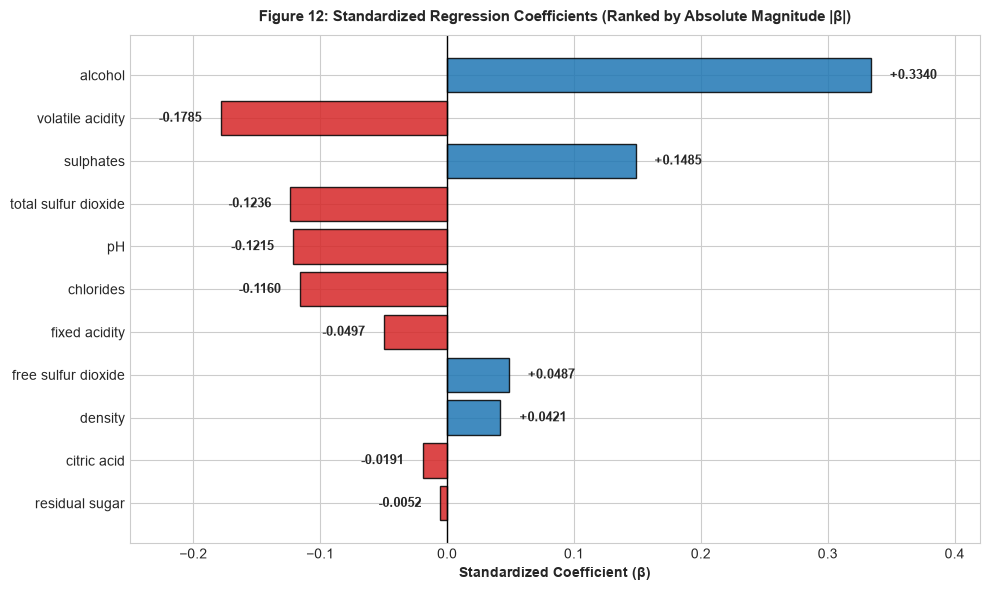

In [22]:
# Figure 12: Standardized Coefficients Bar Chart
scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)

reg_std = LinearRegression()
reg_std.fit(X_train_scaled, y_train)

std_coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Std_Coef': reg_std.coef_,
    'Abs_Coef': np.abs(reg_std.coef_)
}).sort_values(by='Abs_Coef', ascending=True)

plt.figure(figsize=(10, 6))
colors = ['#1f77b4' if c > 0 else '#d62728' for c in std_coef_df['Std_Coef']]
bars = plt.barh(std_coef_df['Feature'], std_coef_df['Std_Coef'], color=colors, edgecolor='black', alpha=0.85)

for bar, val in zip(bars, std_coef_df['Std_Coef']):
    offset = 0.015 if val >= 0 else -0.015
    ha = 'left' if val >= 0 else 'right'
    plt.text(val + offset, bar.get_y() + bar.get_height()/2, f'{val:+.4f}', 
             va='center', ha=ha, fontsize=9, fontweight='bold')

plt.axvline(0, color='black', linewidth=1)
plt.title('Figure 12: Standardized Regression Coefficients (Ranked by Absolute Magnitude |β|)', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Standardized Coefficient (β)', fontsize=10, fontweight='bold')
plt.xlim(-0.25, 0.42)
plt.tight_layout()
plt.savefig('figures/cs5_04_standardized_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

std_coef_df.sort_values(by='Abs_Coef', ascending=False).to_csv('results/cs5_task3_standardized_coefs.csv', index=False)


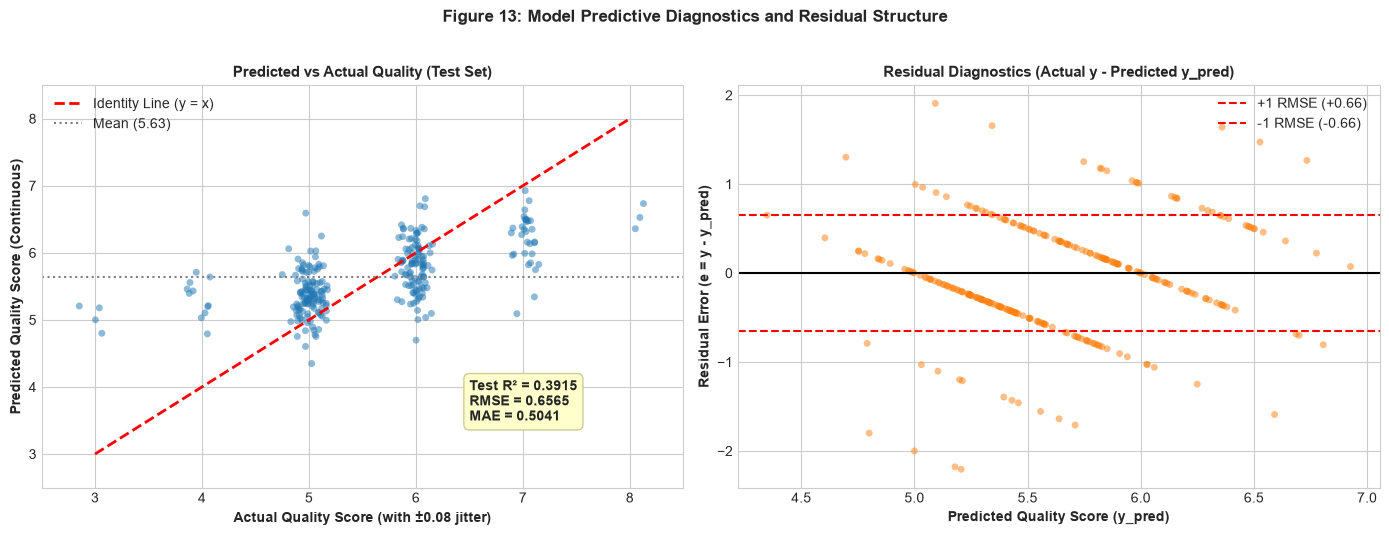

In [23]:
# Figure 13: Predicted vs Actual & Residual Diagnostics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: Predicted vs Actual with jitter
jitter = np.random.normal(0, 0.08, size=len(y_test))
ax1.scatter(y_test + jitter, y_pred_test, color='#1f77b4', alpha=0.5, edgecolors='none', s=25)
ax1.plot([3, 8], [3, 8], 'r--', linewidth=2, label='Identity Line (y = x)')
ax1.axhline(y_train.mean(), color='gray', linestyle=':', label=f'Mean (5.63)')

ax1.annotate(f'Test R² = {r2_test:.4f}\nRMSE = {rmse:.4f}\nMAE = {mae:.4f}', 
             xy=(7, 4), xytext=(6.5, 3.5),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', facecolor='#ffffcc', edgecolor='#cccc99'))

ax1.set_title('Predicted vs Actual Quality (Test Set)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Actual Quality Score (with ±0.08 jitter)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Predicted Quality Score (Continuous)', fontsize=10, fontweight='bold')
ax1.set_xlim(2.5, 8.5)
ax1.set_ylim(2.5, 8.5)
ax1.legend(loc='upper left')

# Right: Residuals vs Predicted
residuals = y_test - y_pred_test
ax2.scatter(y_pred_test, residuals, color='#ff7f0e', alpha=0.5, edgecolors='none', s=25)
ax2.axhline(0, color='black', linewidth=1.5)
ax2.axhline(rmse, color='red', linestyle='--', label=f'+1 RMSE (+{rmse:.2f})')
ax2.axhline(-rmse, color='red', linestyle='--', label=f'-1 RMSE (-{rmse:.2f})')

ax2.set_title('Residual Diagnostics (Actual y - Predicted y_pred)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Predicted Quality Score (y_pred)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Residual Error (e = y - y_pred)', fontsize=10, fontweight='bold')
ax2.legend(loc='upper right')

plt.suptitle('Figure 13: Model Predictive Diagnostics and Residual Structure', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/cs5_05_predicted_vs_actual_residuals.png', dpi=150, bbox_inches='tight')
plt.show()


**Diagnostic Observations:**
1. **Shrinkage Toward the Mean:** Predictions are compressed into a narrow continuous band between 5.0 and 6.5. Because wine quality is a discrete ordinal target (integers 3 to 8), continuous linear regression pulls extreme wines toward the training mean (5.63), consistently underpredicting top-tier wines (score 7-8) and overpredicting poor wines (score 3-4).
2. **Parallel Residual Lines:** The residual plot exhibits parallel downward lines ($e = k - y_{	ext{pred}}$) corresponding to each discrete score integer $k$. This confirms that residuals are constrained by target discreteness rather than pure random gaussian error.


## 5. Task 4: Business Decision-Making & Practical Limitations

### Task 4a: Recommended Laboratory Screening Measurements
Based on statistical significance, correlation strength, and standardized effect sizes, the winery should implement automated laboratory screening on two primary markers:
1. **Alcohol Content:** Strongest positive correlation ($r = +0.4803$), largest positive standardized coefficient ($eta = +0.3340$), and $p < 0.0001$. Higher alcohol indicates proper grape maturity and complete, sound fermentation.
2. **Volatile Acidity:** Second strongest correlation ($r = -0.3952$), largest negative standardized coefficient ($eta = -0.1785$), and $p < 0.0001$. Elevated volatile acidity indicates bacterial contamination and acetic acid spoilage.

### Task 4b: Model Reliability for Sensory Panel Replacement
**The model cannot and should not replace certified human sensory tasting panels.**
- With an $R^2$ of $0.3915$ (explaining only ~39% of variance) and an RMSE of $0.6565$ quality points on a discrete scale, the model's predictions frequently cross an entire quality rating tier.
- Chemical regression fails to measure complex sensory dimensions such as aroma balance, tannin texture, finish, and bouquet.
- **Recommended Role:** Deploy the model as an automated, low-cost **vat pre-screening tool** to flag chemically flawed wine batches before submitting candidate wines to human tasting panels.

### Task 4c: Real-World Limitations
1. **Regional & Varietal Specificity:** The data originates exclusively from red Vinho Verde wines from northern Portugal. Chemical thresholds do not generalize to other varietals (e.g. Cabernet Sauvignon) or regions.
2. **Ordinal Target Discreteness & Subjectivity:** The target variable is an ordinal median score from human experts, introducing sensory subjectivity that a continuous linear equation cannot fully capture.
3. **Severe Class Imbalance:** Over 81.8% of wines are scored 5 or 6, providing insufficient training data for poor (scores 3-4) and outstanding (scores 7-8) wines.


---

## References
1. **Shmueli, G., and Bruce, P. C. (2016).** *Data Mining for Business Analytics: Concepts, Techniques, and Applications in Python*. John Wiley & Sons.
2. **Cortez, P., Cerdeira, A., Almeida, F., Matos, T., and Reis, J. (2009).** Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, Elsevier, 47(4):547-553.
3. **Pedregosa, F., et al. (2011).** Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
4. **Seabold, S., and Perktold, J. (2010).** Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.
